In [2]:
import os
import typing
from sklearn.gaussian_process.kernels import *
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
import matplotlib.pyplot as plt
from matplotlib import cm
from tqdm import tqdm


# Set `EXTENDED_EVALUATION` to `True` in order to visualize your predictions.
EXTENDED_EVALUATION = False
EVALUATION_GRID_POINTS = 300  # Number of grid points used in extended evaluation

# Cost function constants
COST_W_UNDERPREDICT = 50.0
COST_W_NORMAL = 1.0


# Model

In [214]:
class Model(object):
    """
    Model for this task.
    You need to implement the fit_model and predict_pollution methods
    without changing their signatures, but are allowed to create additional methods.
    """

    def __init__(self):
        """
        Initialize your model here.
        We already provide a random number generator for reproducibility.
        """
        self.rng = np.random.default_rng(seed=0)
        # Initialize kernel as RBF
        #self.kernel = RBF(length_scale=5e-4, length_scale_bounds=(1e-5,1e-2))
        #self.kernel = Matern(length_scale=1e-2, length_scale_bounds=(1e-3, 1e-1))

        self.nu = 0.5

        self.kernel = (ConstantKernel(30, constant_value_bounds=(1e-1, 1e2)) 
        * Matern(length_scale=1e-2, nu = self.nu, length_scale_bounds=(1e-3, 1e-1))
        + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-3, 1e2)))

        # Define number of processes
        self.n_processes = 64 # Must be a square number
        self.n_window  = 0.15 
        self.stride = (1 - self.n_window) / (np.sqrt(self.n_processes) - 1)
        self.GPs = [] 
        self.k = 3
        for i in range(self.n_processes):
            GPi = GaussianProcessRegressor(kernel=self.kernel, normalize_y=True, n_restarts_optimizer=9)
            self.GPs.append(GPi)


    
    def classify_zones(self, n_window, stride, coordinates):
        """
        Overlapping square windows of side n_window, shifted by stride, on [0,1]^2.
        Requires n_window + k*stride == 1 for some integer k.
        Returns (N, (k+1)**2) binary array; entry [n, i*(k+1)+j] = 1 if point n
        lies in window (row i along y, column j along x).
        """
        k_float = (1 - n_window) / stride
        k = int(round(k_float))
        if not np.isclose(k, k_float):
            raise ValueError("n_window + k*stride must equal 1 for integer k")
        n_per_axis = k + 1

        starts = np.arange(n_per_axis) * stride            # (n_per_axis,)
        x = coordinates[:, 0][:, None]                     # (N, 1)
        y = coordinates[:, 1][:, None]

        in_x = (x >= starts) & (x < starts + n_window)     # (N, n_per_axis)
        in_y = (y >= starts) & (y < starts + n_window)
        # include the right/top edge in the last window
        in_x[:, -1] |= np.isclose(x[:, 0], 1.0)
        in_y[:, -1] |= np.isclose(y[:, 0], 1.0)

        N = coordinates.shape[0]
        return (in_y[:, :, None] & in_x[:, None, :]).reshape(N, -1).astype(float)

    # Don't change the name or the signature of this function
    def fit_model(self, train_coordinates: np.ndarray, train_pollution_targets: np.ndarray, train_residential_flags: np.ndarray):
        """
        Fit your model on the given training data.
        :param train_coordinates: Training features as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param train_pollution_targets: Training pollution concentrations as a 1d NumPy float array of shape (NUM_SAMPLES,)
        :param train_residential_flags: Binary variable denoting whether the 2D training point is in the residential area (1) or not (0)
        """
        n_window = self.n_window 
        stride = self.stride
        char_funcs = self.classify_zones(n_window, stride, train_coordinates)
        bezirke_training = []
        bezirke_targets = []

        # DATA PREPROCESSING
        print('DATA PREPROCESSING')
        for i in tqdm(range(self.n_processes)):
            # Find training data for this neighborhood 
            bezirk_i_training = []
            bezirk_i_targets = []
            for k in range(train_coordinates.shape[0]):
                if char_funcs[k, i] == 1 :
                    bezirk_i_training.append(train_coordinates[k]) 
                    bezirk_i_targets.append(train_pollution_targets[k]) 

            # Cast to Numpy arrays
            bezirk_i_training = np.array(bezirk_i_training)
            bezirke_training.append(bezirk_i_training)
            bezirk_i_targets = np.array(bezirk_i_targets)
            bezirke_targets.append(bezirk_i_targets)

        # FITTING LOOP
        print('FITTING LOOP')
        import time
        for i in range(self.n_processes):
            t0 = time.perf_counter()
            self.GPs[i].fit(bezirke_training[i], bezirke_targets[i])
            print(i, len(bezirke_training[i]), f"{time.perf_counter() - t0:.2f}s")
       
        pass

    # Don't change the name or the signature of this function
    def predict_pollution(self, test_coordinates: np.ndarray, test_residential_flags: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Predict the pollution concentration for a given set of city_areas.
        :param test_coordinates: city_areas as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param test_residential_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
        :return:
            Tuple of three 1d NumPy float arrays, each of shape (NUM_SAMPLES,),
            containing your predictions, the GP posterior mean, and the GP posterior stddev (in that order)
        """

        # TODO: Use your GP to estimate the posterior mean and stddev for each city_area here
        gp_mean = np.zeros(test_coordinates.shape[0], dtype=float)
        gp_std = np.zeros(test_coordinates.shape[0], dtype=float)

        # Extract characteristic functions (NUM_SAMPLES, n_zones)
        char_funcs = self.classify_zones(self.n_window, self.stride, test_coordinates)
        GP_means = [] 
        GP_stds = [] 
        for i in range(self.n_processes):
            GPi_means, GPi_stds = self.GPs[i].predict(test_coordinates, return_std=True)
            GP_means.append(GPi_means)
            GP_stds.append(GPi_stds)


        GP_means = np.array(GP_means).T # (NUM_SAMPLES, n_processes)
        GP_stds = np.array(GP_stds).T # (NUM_SAMPLES, n_processes)

        prec = char_funcs / (GP_stds ** 2) # Precision is high for small standard deviations

        #stds = np.max(GP_stds * char_funcs, axis=1)

        tot_zones = np.sum(char_funcs, axis=1)

        tot_prec = np.sum(prec, axis=1) # (NUM_SAMPLES,) How many areas does a given point belong to

        tot = tot_prec / tot_zones

        stds = np.sqrt(1 / tot)

        gp_std = stds

        GP_means_relevant = np.sum(GP_means * prec, axis=1) / tot_prec

        # TODO: Use the GP posterior to form your predictions here
        predictions = GP_means_relevant + self.k * stds * test_residential_flags

        return predictions, gp_mean, gp_std


# Cost and Helper functions

In [138]:
# You don't have to change this function
def calculate_cost(ground_truth: np.ndarray, predictions: np.ndarray, residential_flags: np.ndarray) -> float:
    """
    Calculates the cost of a set of predictions.

    :param ground_truth: Ground truth pollution levels as a 1d NumPy float array
    :param predictions: Predicted pollution levels as a 1d NumPy float array
    :param residential_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
    :return: Total cost of all predictions as a single float
    """
    assert ground_truth.ndim == 1 and predictions.ndim == 1 and ground_truth.shape == predictions.shape

    # Unweighted cost
    cost = (ground_truth - predictions) ** 2
    weights = np.ones_like(cost) * COST_W_NORMAL

    # Case i): underprediction
    mask = (predictions < ground_truth) & [bool(residential_flag) for residential_flag in residential_flags]
    weights[mask] = COST_W_UNDERPREDICT

    # Weigh the cost and return the average
    return np.mean(cost * weights)


# You don't have to change this function
def is_inside_circle(coordinate, circle_parameters):
    """
    Checks if a coordinate is inside a circle.
    :param coordinate: 2D coordinate
    :param circle_parameters: 3D coordinate of the circle center and its radius
    :return: True if the coordinate is inside the circle, False otherwise
    """
    return (coordinate[0] - circle_parameters[0])**2 + (coordinate[1] - circle_parameters[1])**2 < circle_parameters[2]**2

# You don't have to change this function
def determine_residential_flags(grid_coordinates):
    """
    Determines the city_area index for each coordinate in the visualization grid.
    :param grid_coordinates: 2D coordinates of the visualization grid
    :return: 1D array of city_area indexes
    """
    # Circles coordinates
    circles = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])

    residential_flags = np.zeros((grid_coordinates.shape[0],))

    for i,coordinate in enumerate(grid_coordinates):
        residential_flags[i] = any([is_inside_circle(coordinate, circ) for circ in circles])

    return residential_flags


# Don't change the name or the signature of this function
def perform_extended_model_evaluation(model: Model, output_dir: str = '/results'):
    """
    Visualizes the predictions of a fitted model.
    :param model: Fitted model to be visualized
    :param output_dir: Directory in which the visualizations will be stored
    """
    print('Performing extended evaluation')

    # Visualize on a uniform grid over the entire coordinate system
    grid_lat, grid_lon = np.meshgrid(
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
    )
    visualization_grid = np.stack((grid_lon.flatten(), grid_lat.flatten()), axis=1)
    grid_residential_flags = determine_residential_flags(visualization_grid)

    # Obtain predictions, means, and stddevs over the entire map
    predictions, gp_mean, gp_stddev = model.predict_pollution(visualization_grid, grid_residential_flags)
    predictions = np.reshape(predictions, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))
    gp_mean = np.reshape(gp_mean, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))

    vmin, vmax = 0.0, 65.0

    # Plot the actual predictions
    fig, ax = plt.subplots()
    ax.set_title('Extended visualization of task 1')
    im = ax.imshow(predictions, vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax)

    # Save figure to pdf
    figure_path = os.path.join(output_dir, 'extended_evaluation.pdf')
    fig.savefig(figure_path)
    print(f'Saved extended evaluation to {figure_path}')

    plt.show()

# You do not need to change the name or the signature of this function; convenience helper used by main() 
def get_city_area_data(train_x: np.ndarray, test_x: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Extracts the city_area information from the training and test features.
    :param train_x: Training features
    :param test_x: Test features
    :return: Tuple of (training features' 2D coordinates, training features' city_area information,
        test features' 2D coordinates, test features' city_area information)
    """
    train_coordinates = np.zeros((train_x.shape[0], 2), dtype=float)
    train_residential_flags = np.zeros((train_x.shape[0],), dtype=bool)
    test_coordinates = np.zeros((test_x.shape[0], 2), dtype=float)
    test_residential_flags = np.zeros((test_x.shape[0],), dtype=bool)

    train_residential_flags = train_x[:,2]
    test_residential_flags = test_x[:,2]

    train_coordinates = train_x[:,:2]
    test_coordinates = test_x[:,:2]

    test_residential_flags_2 = determine_residential_flags(test_coordinates)
    train_residential_flags_2 = determine_residential_flags(train_coordinates)

    for i in range(len(train_residential_flags)):

        assert train_residential_flags[i] == train_residential_flags_2[i]
        if i < len(test_residential_flags):
            assert test_residential_flags[i] == test_residential_flags_2[i]

    assert train_coordinates.shape[0] == train_residential_flags.shape[0] and test_coordinates.shape[0] == test_residential_flags.shape[0]
    assert train_coordinates.shape[1] == 2 and test_coordinates.shape[1] == 2
    assert train_residential_flags.ndim == 1 and test_residential_flags.ndim == 1

    return train_coordinates, train_residential_flags, test_coordinates, test_residential_flags

# you don't have to change this function


# Visualize Measurements and Residential Areas

(15189, 2)
(15189,)


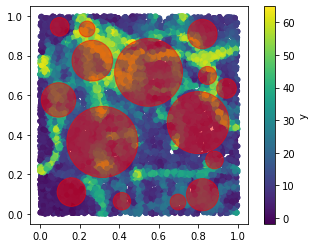

0

In [87]:
def visualize_measurements():

    # Load the training dataset and test features
    train_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
    train_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
    test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)


    # Extract the city_area information
    train_coordinates, train_residential_flags, test_coordinates, test_residential_flags = get_city_area_data(train_x, test_x)
    print(train_coordinates.shape)
    print(train_residential_flags.shape)

       # Plot the actual predictions
    fig, ax = plt.subplots()
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    CIRCLES = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])

    from matplotlib.patches import Circle

    for cx, cy, r in CIRCLES:
        ax.add_patch(Circle((cx, cy), r, facecolor="red", alpha=0.5,
                        edgecolor="red", linewidth=1, zorder=2))
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    fig.colorbar(map, ax=ax, label="y")
    #test = ax.scatter(test_coordinates[:,0], test_coordinates[:,1])
    ax.set_aspect("equal")
    plt.show()
   
    # train_coordinates is an array of shape (n_train, 2). We want do place 
    return 0 

visualize_measurements()


Import the training data and split into training and validation sets

In [88]:
def val_train_split(train_coordinates, train_residential_flags, train_y, split=0.7):
    ''' 
    Creates a test-train split of the data. Split is the proportion of the data to be used for training 
    '''

    # extract number of samples and assert correct shapes
    NUM_SAMPLES = train_coordinates.shape[0]
    assert train_coordinates.shape[1] == 2, 'train_coordinates has wrong shape'
    assert len(train_residential_flags) == NUM_SAMPLES, 'wrong number of residential flags'
    assert len(train_y) == NUM_SAMPLES, 'wrong number of training targets'

    # Get number of training samples and validation samples
    NUM_TRAIN = int(round(NUM_SAMPLES * split))
    NUM_VAL = NUM_SAMPLES - NUM_TRAIN

    rng = np.random.default_rng()
    idxs_train = rng.choice(NUM_SAMPLES, size=NUM_TRAIN, replace=False)
    #idxs_train = np.random.randint(0, NUM_SAMPLES, NUM_TRAIN, )
    idxs_val = np.arange(NUM_SAMPLES)
    idxs_val = np.delete(idxs_val, idxs_train)
    '''
    for i in range(NUM_SAMPLES):
        if i in idxs_train:
            idxs_val = np.delete(idxs_val, i)
    '''
    
    val_coordinates = train_coordinates[idxs_val]
    train_coordinates = train_coordinates[idxs_train]
    print('NUM_VALS', NUM_VAL)
    print('shape val_coordinates', val_coordinates.shape[0])
    assert val_coordinates.shape[0] == NUM_VAL, 'Wrong number of validation samples'

    val_residential_flags = train_residential_flags[idxs_val]
    train_residential_flags = train_residential_flags[idxs_train]

    val_y = train_y[idxs_val]
    train_y = train_y[idxs_train]

    return train_coordinates, train_residential_flags, train_y, val_coordinates, val_residential_flags, val_y


In [182]:
    # Load the training dataset and test features
train_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
train_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)

# Extract the city_area information
train_coordinates, train_residential_flags, test_coordinates, test_residential_flags = get_city_area_data(train_x, test_x)

# Perform test-train split
train_coordinates, train_residential_flags, train_y, val_coordinates, val_residential_flags, val_y = val_train_split(train_coordinates, train_residential_flags, train_y)


print(train_coordinates.shape)




NUM_VALS 4557
shape val_coordinates 4557
(10632, 2)


Define the asymetric loss on the validation set

In [212]:

def asymmetric_loss(coords, residential_flags, predictions, targets):
    '''
    Predicts the asymmetric loss given some coordinates, residential flags, predictions and targets. 

    Saves the coordinates of the spots where we underestimated in a residential area
    '''

    # Extract number of samples and assert correct shapes of arguments
    NUM_SAMPLES = coords.shape[0]
    assert NUM_SAMPLES == len(residential_flags), 'WRONG number of residential flags'
    assert NUM_SAMPLES == len(predictions), 'WRONG number of predictions'
    assert NUM_SAMPLES == len(targets), 'WRONG number of targets'

    # Find number of residential areas
    NUM_RESIDENTIAL = np.sum(residential_flags)
    idxs_underestimated = []

    # Find Residuals
    res = targets - predictions 
    weights = np.ones_like(residential_flags)

    for i in range(NUM_SAMPLES):
        if residential_flags[i] and res[i] > 0: 
            weights[i] = 50
            idxs_underestimated.append(i)

    print('number of total residential areas in data', NUM_RESIDENTIAL)
    print('number of underestimations in residential areas:', len(idxs_underestimated))
    print('PROPORTION OF UNDERESTIMATIONS:', len(idxs_underestimated) / NUM_RESIDENTIAL)
    loss = np.mean(weights * (res**2)) 

    print('asymmetric LOSS', loss)

    coords_underestimated_residential = coords[idxs_underestimated]

    return loss, coords_underestimated_residential


def symmetric_loss(coords, residential_flags, predictions, targets):
    '''
    Predicts the symmetric loss given some coordinates, residential flags, predictions and targets. 

    Saves the coordinates of the spots where we underestimated in a residential area
    '''

    # Extract number of samples and assert correct shapes of arguments
    NUM_SAMPLES = coords.shape[0]
    assert NUM_SAMPLES == len(residential_flags), 'WRONG number of residential flags'
    assert NUM_SAMPLES == len(predictions), 'WRONG number of predictions'
    assert NUM_SAMPLES == len(targets), 'WRONG number of targets'

    # Find Residuals
    res = targets - predictions 
    count = 0
    for i in range(len(res)):
        if res[i] > 0:
           count = count + 1 
    loss = np.mean(res**2) 

    print('Proportion of underestimates:', count / NUM_SAMPLES )
    print('symmetric LOSS', loss)


    return loss, count

def scatter_pred_std(predictions, targets, stds):
    ''' 
    Creates a scatterplot of the loss at each point and its corresponding standard deviation.
    We would think that in average, the smaller the loss at each point the smaller the uncertainty 
    of the GP that produced it. We want to see if a scatterplot is informative. 
    '''
    NUM_SAMPLES = len(predictions)
    assert NUM_SAMPLES == len(targets), 'wrong size fo targets'
    assert NUM_SAMPLES == len(stds), 'wrong size of stds'

    res = targets - predictions
    loss = res**2

    within = np.sum(np.abs(res) < 2 * stds)
    prop = within / NUM_SAMPLES

    print('percentage of data within two sigma', 100 * prop, '%')


    fig, ax = plt.subplots()
    ax.scatter(loss, stds,
        facecolors="none", edgecolors="black", linewidths=1.5,
        s=60, marker="o", zorder=4, label="(x = loss, y = stds) pairs")

    plt.show()

def histogram_pred_std(predictions, targets, stds):
    ''' 
    Finds a histogram of the distribution of the losses. 
    '''
    NUM_SAMPLES = len(predictions)
    assert NUM_SAMPLES == len(targets), 'wrong size fo targets'
    assert NUM_SAMPLES == len(stds), 'wrong size of stds'

    res = targets - predictions
    
    # prepare histogram from -10 to 10 in steps of 1
    lower = -10
    upper = 10
    n_bins = 20 
    bounds = np.linspace(lower, upper, n_bins + 1)
    hist = np.zeros_like(bounds) 

    for i in range(n_bins):
        for n in range(NUM_SAMPLES):
            if bounds[i] < res[n] and res[n] <= bounds[i + 1]:
                hist[i] = hist[i] + 1

    hist = hist / np.sum(hist)

    
    # Can we do a gaussian fit? 
    from scipy.optimize import curve_fit

    F = lambda x, mu, std: 1 / np.sqrt((2 * np.pi * std**2)) * np.exp(-0.5 * (x - mu) **2 / std**2)

    popt, pcov = curve_fit(F, bounds, hist)
    mu = popt[0]
    std = popt[1]

    plt.figure()
    plt.title('Distribution of Residuals')
    plt.bar(bounds, hist, label='Residual distribution')
    plt.plot(bounds, F(bounds, popt[0], popt[1]), label='Gaussian fit \n$\mu$ = ' + str(round(mu, 2)) + '\n$\sigma$ = ' + str(round(std, 2)), color='r')
    plt.legend(loc='best') 
    plt.show




    pass



        

DATA PREPROCESSING


100%|██████████| 64/64 [00:00<00:00, 348.31it/s]

FITTING LOOP


0 222 1.71s
1 206 0.89s
2 193 0.71s
3 129 0.43s
4 119 0.46s
5 137 0.49s
6 141 0.41s
7 145 0.53s
8 234 0.97s
9 154 0.49s
10 266 1.19s
11 162 0.53s
12 202 0.73s
13 177 0.64s
14 169 0.60s
15 174 0.67s
16 227 0.92s
17 132 0.43s
18 251 1.09s
19 163 0.59s
20 137 0.44s
21 161 0.55s
22 108 0.33s
23 130 0.41s
24 281 1.30s


/usr/local/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 0.1. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


25 138 0.57s
26 187 0.71s
27 215 0.84s
28 152 0.50s
29 172 0.61s
30 110 0.40s
31 210 0.76s
32 288 1.62s
33 184 0.61s
34 312 1.63s
35 165 0.65s
36 176 0.85s
37 194 3.07s
38 212 1.02s
39 263 1.17s
40 257 1.14s
41 275 1.51s
42 506 5.40s
43 503 6.22s
44 189 1.13s
45 235 1.59s
46 314 2.83s
47 289 2.67s
48 242 1.74s
49 326 3.00s
50 608 9.14s
51 538 7.29s
52 281 1.62s
53 308 1.92s
54 515 6.48s
55 362 2.85s
56 163 1.08s
57 476 5.63s
58 446 4.53s
59 311 1.97s
60 176 0.74s
61 239 1.31s
62 257 1.37s
63 130 0.55s
DATA PREPROCESSING


... (4 outputs left out)

100%|██████████| 64/64 [00:00<00:00, 142.91it/s]


FITTING LOOP
0 222 2.45s
1 206 1.16s
2 193 1.05s
3 129 0.67s
4 119 0.92s
5 137 1.23s
6 141 1.38s
7 145 1.08s
8 234 1.61s
9 154 0.80s
10 266 3.02s
11 162 1.09s
12 202 1.97s
13 177 1.31s
14 169 1.50s
15 174 1.24s
16 227 1.82s
17 132 0.74s
18 251 1.55s
19 163 1.17s
20 137 1.10s
21 161 0.98s
22 108 1.88s
23 130 1.11s
24 281 2.74s


/usr/local/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 0.1. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


25 138 0.76s
26 187 1.02s
27 215 1.09s
28 152 0.66s
29 172 0.80s
30 110 0.60s
31 210 1.01s
32 288 1.82s
33 184 0.87s
34 312 2.19s
35 165 0.83s
36 176 0.82s
37 194 1.27s
38 212 1.43s
39 263 1.91s
40 257 1.74s
41 275 1.74s
42 506 6.59s
43 503 7.80s
44 189 0.96s
45 235 1.77s
46 314 2.97s
47 289 1.71s
48 242 1.41s
49 326 2.28s
50 608 11.75s
51 538 10.75s
52 281 2.23s
53 308 3.44s
54 515 7.47s
55 362 3.30s
56 163 0.86s
57 476 5.42s
58 446 5.10s
59 311 2.04s
60 176 0.88s
61 239 1.78s
62 257 2.36s
63 130 1.00s
================== MODEL NU: 0.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 9
PROPORTION OF UNDERESTIMATIONS: 0.004281636536631779
asymmetric LOSS 20.825809956076387
Proportion of underestimates: 0.25806451612903225
symmetric LOSS 20.728295363190846
percentage of data within two sigma 57.73535220539829 %


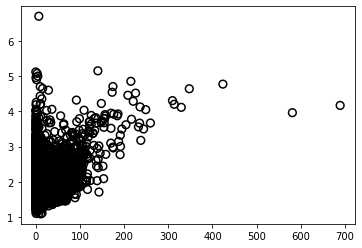

================== MODEL NU: 1.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 9
PROPORTION OF UNDERESTIMATIONS: 0.004281636536631779
asymmetric LOSS 20.825810132543328
Proportion of underestimates: 0.25806451612903225
symmetric LOSS 20.728295555386698
percentage of data within two sigma 57.73535220539829 %


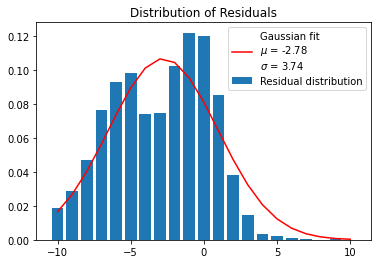

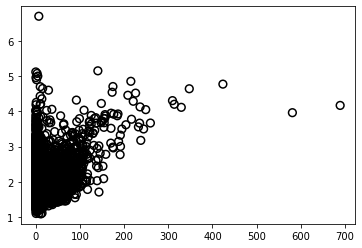

================== MODEL NU: 2.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 9
PROPORTION OF UNDERESTIMATIONS: 0.004281636536631779
asymmetric LOSS 20.825810519957635
Proportion of underestimates: 0.25806451612903225
symmetric LOSS 20.72829595936605
percentage of data within two sigma 57.73535220539829 %


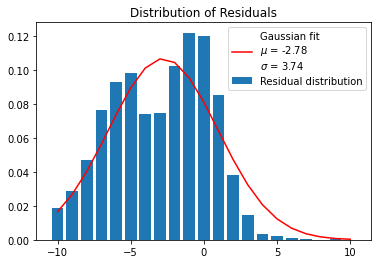

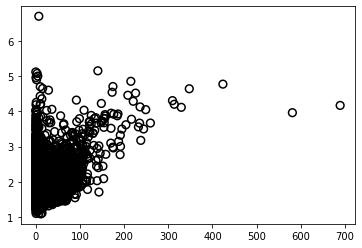

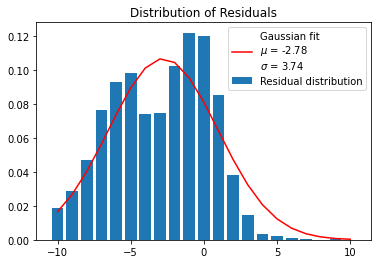

In [215]:
models = []
for nu in [0.5, 1.5, 2.5]:
    model_nu = Model()
    model_nu.nu = nu
    model_nu.fit_model(train_coordinates, train_y, train_residential_flags)
    models.append(model_nu)

    

================== MODEL NU: 0.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 291
PROPORTION OF UNDERESTIMATIONS: 0.1384395813510942
asymmetric LOSS 10.723066939983811
Proportion of underestimates: 0.31994733377221857
symmetric LOSS 5.825681226435759
percentage of data within two sigma 90.3006363835857 %


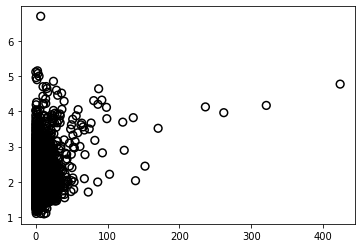

================== MODEL NU: 1.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 291
PROPORTION OF UNDERESTIMATIONS: 0.1384395813510942
asymmetric LOSS 10.723066636230758
Proportion of underestimates: 0.31994733377221857
symmetric LOSS 5.82568125354328
percentage of data within two sigma 90.3006363835857 %


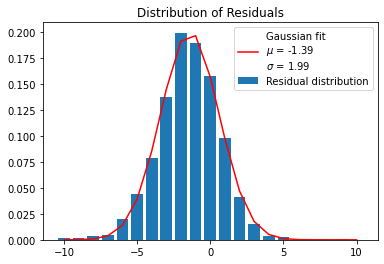

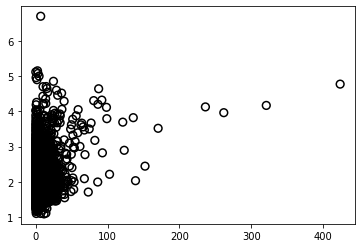

================== MODEL NU: 2.5 =====================
number of total residential areas in data 2102.0
number of underestimations in residential areas: 291
PROPORTION OF UNDERESTIMATIONS: 0.1384395813510942
asymmetric LOSS 10.723066716996469
Proportion of underestimates: 0.31994733377221857
symmetric LOSS 5.825681338335908
percentage of data within two sigma 90.3006363835857 %


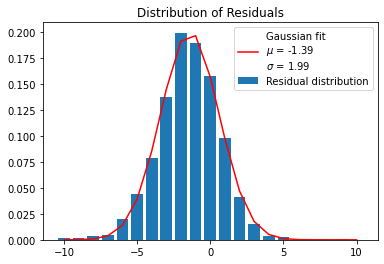

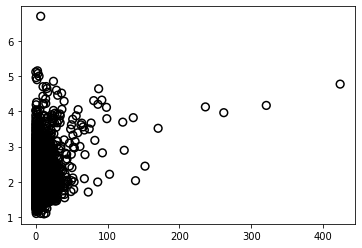

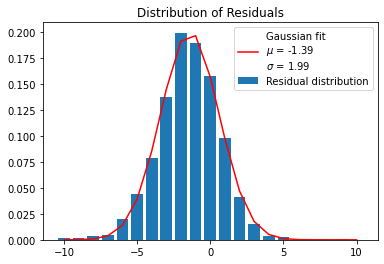

In [216]:
for model_nu in models:
    print('================== MODEL NU:', model_nu.nu, '=====================')
    model_nu.k = 1
    predictions_val, predictions_mean, predictions_std = model_nu.predict_pollution(val_coordinates, val_residential_flags)

    loss, under_coords = asymmetric_loss(val_coordinates, val_residential_flags, predictions_val, val_y)
    symm_loss, count = symmetric_loss(val_coordinates, val_residential_flags, predictions_val, val_y)

    scatter_pred_std(predictions_val, val_y, predictions_std)
    histogram_pred_std(predictions_val, val_y, predictions_std)

In [206]:

    # Fit the model
print('Training model')
model = Model()
model.fit_model(train_coordinates, train_y, train_residential_flags)

    # Predict on the test features
print('Predicting on test features')
predictions = model.predict_pollution(test_coordinates, test_residential_flags)
print(predictions)

Training model
DATA PREPROCESSING


100%|██████████| 64/64 [00:00<00:00, 341.60it/s]

FITTING LOOP


0 222 1.27s
1 206 0.56s
2 193 0.61s
3 129 0.37s
4 119 0.30s
5 137 0.34s
6 141 0.36s
7 145 0.36s
8 234 0.86s
9 154 0.39s
10 266 1.74s
11 162 0.37s
12 202 0.52s
13 177 0.50s
14 169 0.49s
15 174 0.45s
16 227 0.60s
17 132 0.31s
18 251 0.79s
19 163 0.39s
20 137 0.31s
21 161 0.37s
22 108 0.21s
23 130 0.30s
24 281 0.92s


/usr/local/lib/python3.9/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 0.1. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


25 138 0.33s
26 187 0.46s
27 215 0.61s
28 152 0.33s
29 172 0.44s
30 110 0.23s
31 210 0.57s
32 288 1.01s
33 184 0.47s
34 312 1.25s
35 165 0.39s
36 176 0.53s


/usr/local/lib/python3.9/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


37 194 0.70s
38 212 0.60s
39 263 0.92s
40 257 0.76s
41 275 0.86s
42 506 4.06s
43 503 3.86s
44 189 0.44s
45 235 0.66s
46 314 1.25s
47 289 0.97s
48 242 0.67s
49 326 1.25s
50 608 6.79s
51 538 4.75s
52 281 0.91s
53 308 1.15s
54 515 4.17s
55 362 1.77s
56 163 0.41s
57 476 3.23s
58 446 2.75s
59 311 1.17s
60 176 0.43s
61 239 0.72s
62 257 0.85s
63 130 0.33s
Predicting on test features
(array([27.56689501, 56.17161292, 63.92294361, ..., 41.22322321,
       55.11141841, 58.3919117 ]), array([0., 0., 0., ..., 0., 0., 0.]), array([2.38988638, 1.79195893, 1.58423462, ..., 2.16853695, 1.47750823,
       1.56296116]))


Test fit on the validation set

64
number of total residential areas in data 2102.0
number of underestimations in residential areas: 1035
PROPORTION OF UNDERESTIMATIONS: 0.4923882017126546
asymmetric LOSS 37.26362048753555
Proportion of underestimates: 0.48321263989466756
symmetric LOSS 3.789946991001732
percentage of data within two sigma 95.80864603906079 %


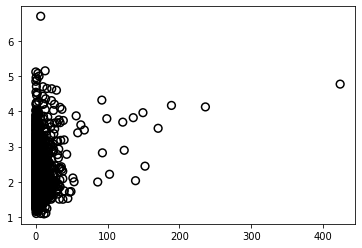

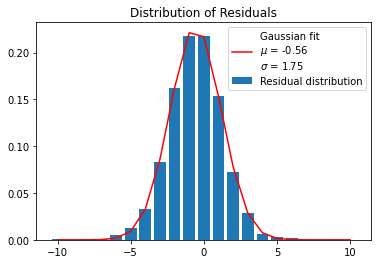

In [213]:
model.k = 0  

predictions_val, predictions_mean, predictions_std = model.predict_pollution(val_coordinates, val_residential_flags)
print(model.n_processes)

loss, under_coords = asymmetric_loss(val_coordinates, val_residential_flags, predictions_val, val_y)
symm_loss, count = symmetric_loss(val_coordinates, val_residential_flags, predictions_val, val_y)

scatter_pred_std(predictions_val, val_y, predictions_std)
histogram_pred_std(predictions_val, val_y, predictions_std)

In [165]:
for gp in model.GPs[:3]:
    print(gp.kernel_, gp.normalize_y, gp.alpha)

4.34**2 * Matern(length_scale=0.01, nu=1.5) * WhiteKernel(noise_level=0.0532) True 1e-10
2.12**2 * Matern(length_scale=0.00165, nu=1.5) * WhiteKernel(noise_level=0.222) True 1e-10
4.34**2 * Matern(length_scale=0.01, nu=1.5) * WhiteKernel(noise_level=0.0532) True 1e-10


See where exactly we underestimate. Is there any systematicity there?

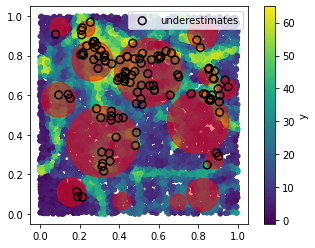

0

In [209]:
def visualize_underestimates():


       # Plot the actual predictions
    fig, ax = plt.subplots()
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    CIRCLES = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])

    from matplotlib.patches import Circle

    for cx, cy, r in CIRCLES:
        ax.add_patch(Circle((cx, cy), r, facecolor="red", alpha=0.5,
                        edgecolor="red", linewidth=1, zorder=2))
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    ax.scatter(under_coords[:, 0], under_coords[:, 1],
           facecolors="none", edgecolors="black", linewidths=1.5,
           s=60, marker="o", zorder=4, label="underestimates")
    ax.legend(loc="upper right")
    #ax.scatter(under_coords[:,0], under_coords[:,1])
    fig.colorbar(map, ax=ax, label="y")
    #test = ax.scatter(test_coordinates[:,0], test_coordinates[:,1])
    ax.set_aspect("equal")
    plt.show()
   
    # train_coordinates is an array of shape (n_train, 2). We want do place 
    return 0 

visualize_underestimates()

In [58]:
print(predictions[0])

EXTENDED_EVALUATION = True
if EXTENDED_EVALUATION:
    perform_extended_model_evaluation(model, output_dir='.')

[27.91308967 59.96238997 59.24308403 ... 34.66399149 46.3302887
 58.25952345]
Performing extended evaluation


KeyboardInterrupt: 